# Calculus - 微积分

In [ ]:
import numpy as np
from matplotlib_inline import backend_inline
from d2l import torch as d2l

from typing import Callable

def f(x):
    return 3 * x ** 2 - 4 * x

def numerical_lim(f: Callable[[float], float], x: float, h: float): # 这里f是一个函数，x是一个数值，h是一个小数值
    return (f(x + h) - f(x)) / h

h = 0.1
for i in range(5):
    print(f'h={h:.5f}, numerical limit={numerical_lim(f, 1, h):.5f}')
    h *= 0.1

h=0.10000, numerical limit=2.30000
h=0.01000, numerical limit=2.03000
h=0.00100, numerical limit=2.00300
h=0.00010, numerical limit=2.00030
h=0.00001, numerical limit=2.00003


## Visualization Operation - 可视化操作 

X in plot 1: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7
 1.8 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9]
Y in plot 1: [array([ 0.  , -0.37, -0.68, -0.93, -1.12, -1.25, -1.32, -1.33, -1.28,
       -1.17, -1.  , -0.77, -0.48, -0.13,  0.28,  0.75,  1.28,  1.87,
        2.52,  3.23,  4.  ,  4.83,  5.72,  6.67,  7.68,  8.75,  9.88,
       11.07, 12.32, 13.63]), array([-3. , -2.8, -2.6, -2.4, -2.2, -2. , -1.8, -1.6, -1.4, -1.2, -1. ,
       -0.8, -0.6, -0.4, -0.2,  0. ,  0.2,  0.4,  0.6,  0.8,  1. ,  1.2,
        1.4,  1.6,  1.8,  2. ,  2.2,  2.4,  2.6,  2.8])]


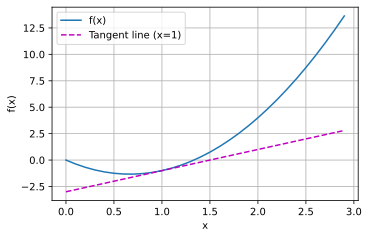

In [18]:
# 为了对导数的这种解释进行可视化，我们将使用matplotlib， 这是一个Python中流行的绘图库。
# 注意，注释#@save是一个特殊的标记，会将对应的函数、类或语句保存在d2l包中。(仅仅在该包中生效，是一种特殊的定义)
#  因此，以后无须重新定义就可以直接调用它们（例如，d2l.use_svg_display()）。
def use_svg_display():  #@save
    """使用svg格式在Jupyter中显示绘图"""
    backend_inline.set_matplotlib_formats('svg')


def set_figsize(figsize=(3.5, 2.5)):  #@save
    """设置matplotlib的图表大小"""
    use_svg_display()
    d2l.plt.rcParams['figure.figsize'] = figsize


#@save
def set_axes(axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend):
    """设置matplotlib的轴"""
    axes.set_xlabel(xlabel)
    axes.set_ylabel(ylabel)
    axes.set_xscale(xscale)
    axes.set_yscale(yscale)
    axes.set_xlim(xlim)
    axes.set_ylim(ylim)
    if legend:
        axes.legend(legend)
    axes.grid()


#@save
def plot(X, Y=None, xlabel=None, ylabel=None, legend=None, xlim=None,
         ylim=None, xscale='linear', yscale='linear',
         fmts=('-', 'm--', 'g-.', 'r:'), figsize=(5.5, 3.5), axes=None):
    
    print('X in plot 1:', X)
    print('Y in plot 1:', Y)
    """绘制数据点"""
    # 没有传图例时，使用空列表，避免后续判断出现 None 的分支问题
    if legend is None:
        legend = []

    # 设置画布尺寸并获取当前坐标轴（如果外部没传 axes，就使用当前默认 axes）
    set_figsize(figsize)
    axes = axes if axes else d2l.plt.gca()

    # 判断输入是否是一维序列（如一条曲线的 x 或 y）
    '''(
    (hasattr(X, "ndim") and X.ndim == 1)           # 第一组：检查是否为一维数组
    or 
    (
        isinstance(X, list)                        # 第二组：检查是否为列表
        and 
        (not hasattr(X[0], "__len__"))             # 且元素不是可迭代对象
    )
    )'''
    def has_one_axis(X):
        return (hasattr(X, "ndim") and X.ndim == 1 or isinstance(X, list)
                and not hasattr(X[0], "__len__"))

    # 统一数据格式：把单个序列包装成“序列列表”，便于后面按多条曲线统一处理
    if has_one_axis(X):
        X = [X]
    # print('X in plot 2:', X)
    if Y is None:
        # 只传了一个参数时，默认把它当 Y，X 用空列表占位，绘图时用索引作横轴
        X, Y = [[]] * len(X), X
    elif has_one_axis(Y):
        Y = [Y]
    if len(X) != len(Y):
        # 当 X 只有一组而 Y 有多组时，复用同一组 X 与每一组 Y 配对
        X = X * len(Y)

    # print('X in plot 3:', X)
    # 清空当前坐标轴，再逐条绘制曲线
    axes.cla()
    for x, y, fmt in zip(X, Y, fmts):
        if len(x):
            axes.plot(x, y, fmt)
        else:
            axes.plot(y, fmt)

    # 统一设置坐标轴标签、范围、比例尺和图例
    set_axes(axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend)


x = np.arange(0, 3, 0.1)
# print(x)
plot(x, [f(x), 2 * x - 3], 'x', 'f(x)', legend=['f(x)', 'Tangent line (x=1)'])


x: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7
 1.8 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9]
y1: [ 0.   -0.37 -0.68 -0.93 -1.12 -1.25 -1.32 -1.33 -1.28 -1.17 -1.   -0.77
 -0.48 -0.13  0.28  0.75  1.28  1.87  2.52  3.23  4.    4.83  5.72  6.67
  7.68  8.75  9.88 11.07 12.32 13.63]
y2: [-3.  -2.8 -2.6 -2.4 -2.2 -2.  -1.8 -1.6 -1.4 -1.2 -1.  -0.8 -0.6 -0.4
 -0.2  0.   0.2  0.4  0.6  0.8  1.   1.2  1.4  1.6  1.8  2.   2.2  2.4
  2.6  2.8]


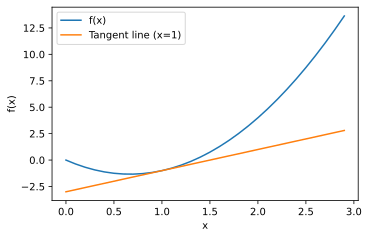

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(0, 3, 0.1)
print('x:', x)
y1 = f(x)
print('y1:', y1)
y2 = 2 * x - 3
print('y2:', y2)

# 设置画布大小
plt.figure(figsize=(5.5, 3.5))


plt.plot(x, y1, label='f(x)')
plt.plot(x, y2, label='Tangent line (x=1)')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.show()

![alt text](image/d2l-2.4-question.png)

f: x**3 - 1/x
f.type: <class 'sympy.core.add.Add'>
f_prime: 3*x**2 + x**(-2)
tangent_eq: 4.0*x - 4.0
tangent_eq_simplified: 4.0*x - 4.0
tangent_str: y = 4.0000*(x - 1.0) + 0.0000
simplified_str: y = 4.0000x + -4.0000
切线方程: y = 4.0000x + -4.0000
详细信息: {'point': (1.0, 0.0), 'slope': 4.0, 'intercept': -4.0, 'tangent_equation': '4.0*x - 4.0', 'simplified_equation': 'y = 4.0000x + -4.0000', 'function_value': 0.0, 'derivative_value': 4.0}


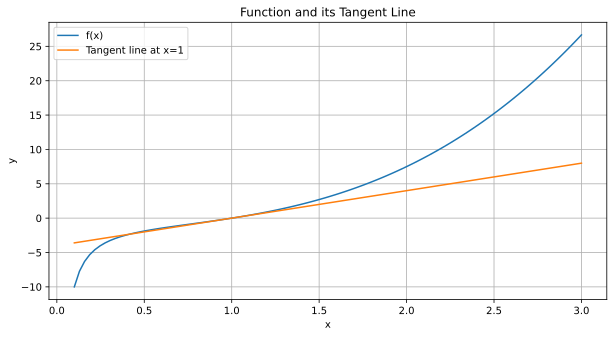

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

def get_tangent_line(polynomial_str, point_x):
    """
    计算多项式函数在某一点的切线方程
    
    参数:
    polynomial_str (str): 多项式函数字符串，例如 "x**2 + 2*x + 1"
    point_x (float): 切点的x坐标
    
    返回:
    str: 切线方程的字符串表示
    dict: 包含切线方程详细信息的字典
    """
    # 1. 定义符号变量
    x = sp.Symbol('x')
    
    # 2. 将字符串转换为SymPy表达式
    try:
        f = sp.sympify(polynomial_str)
    except Exception as e:
        raise ValueError(f"无效的多项式表达式: {e}")
    
    # 3. 计算导数（斜率函数）
    f_prime = sp.diff(f, x) # 求导函数
    print('f:', f)
    print('f.type:', type(f))
    print('f_prime:', f_prime)
    
    # 4. 计算切点处的函数值和导数值
    y0 = f.subs(x, point_x).evalf()
    slope = f_prime.subs(x, point_x).evalf()
    
    # 5. 构建切线方程：y = slope*(x - point_x) + y0
    tangent_eq = slope * (x - point_x) + y0
    print('tangent_eq:', tangent_eq)
    
    # 6. 简化切线方程
    tangent_eq_simplified = sp.simplify(tangent_eq)
    print('tangent_eq_simplified:', tangent_eq_simplified)
    
    # 7. 转换为标准形式：y = mx + b
    m = slope
    b = y0 - slope * point_x
    
    # 8. 格式化输出
    tangent_str = f"y = {m:.4f}*(x - {point_x}) + {y0:.4f}"
    print('tangent_str:', tangent_str)
    simplified_str = f"y = {m:.4f}x + {b:.4f}"
    print('simplified_str:', simplified_str)
    
    # 9. 返回结果
    result = {
        'point': (float(point_x), float(y0)),
        'slope': float(slope),
        'intercept': float(b),
        'tangent_equation': str(tangent_eq_simplified),
        'simplified_equation': simplified_str,
        'function_value': float(y0),
        'derivative_value': float(slope)
    }
    
    return simplified_str, result

# 示例使用
polynomial = "x**3 - (1/x)"
point_x = 1.0
tangent_line, details = get_tangent_line(polynomial, point_x)
print("切线方程:", tangent_line)
print("详细信息:", details)

f_tangent = sp.sympify(details['tangent_equation'])

# 绘制图像
x_vals = np.linspace(0.1, 3, 100)  # 避免x=0的奇点，在区间 [0.1,3] 之间，均匀地生成 100 个数字（包含起点和终点）
# print('x_vals:', x_vals)
y_vals = [sp.sympify(polynomial).subs(sp.Symbol('x'), val).evalf() for val in x_vals]
# print('y_vals:', y_vals)
y_tangent_vals = [f_tangent.subs(sp.Symbol('x'), val).evalf() for val in x_vals]
# print('y_tangent_vals:', y_tangent_vals)
plt.figure(figsize=(10, 5))
plt.plot(x_vals, y_vals, label='f(x)')
plt.plot(x_vals, y_tangent_vals, label='Tangent line at x=1')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Function and its Tangent Line')
plt.legend()
plt.grid()
plt.show()



In [55]:
# 梯度计算
import sympy as sp

def calculate_gradient_symby(function_expr, variables):
    """
    使用 SymPy 计算多元函数的梯度
    
    参数:
    function_expr: 字符串形式的多元函数表达式 (例如 "x**2 + y**2")
    variables: 变量列表 (例如 ["x", "y"])
    
    返回:
    gradient_list: 包含各偏导数的列表
    gradient_vector: 符号向量形式
    """
    # 1. 定义符号变量
    var_symbols = [sp.Symbol(v) for v in variables]
    
    # 2. 将字符串转换为表达式
    try:
        f = sp.sympify(function_expr)
    except Exception as e:
        raise ValueError(f"表达式错误: {e}")
    
    # 3. 计算梯度 (对每个变量求偏导)
    gradient_list = [sp.diff(f, var) for var in var_symbols]
    
    # 4. 构建梯度向量
    gradient_vector = sp.Matrix(gradient_list)
    
    return gradient_vector, gradient_list


# 定义一个二元函数 f(x, y) = x^2 * y + sin(y)
expr = "x**2 * y + sin(y)" 
vars = ["x", "y"]

grad_vec, grad_vals = calculate_gradient_symby(expr, vars)
# grad_vec 是一个符号矩阵，包含了函数在每个变量上的偏导数
# grad_vals 是一个列表，包含了每个变量的偏导数表达式

print(f"函数: f({vars}) = {expr}")
print("-" * 30)
print("梯度向量 (∇f):")
print(grad_vec)
print("\n各分量:")
for i, v in enumerate(vars):
    print(f"∂f/∂{v} = {grad_vals[i]}")

# 如果需要代入具体点求值 (例如 x=1, y=2)
point = {"x": 1, "y": 2}
grad_at_point = grad_vec.subs(point)
print(f"\n在点 ({point['x']}, {point['y']}) 处的梯度值:")
print(grad_at_point.evalf())


# 定义一个二元函数 f(x1, x2) = 3*x1^2 + 5*exp(x2)
expr = "3*x1**2 + 5*exp(x2)" 
vars = ["x1", "x2"]
f3 = sp.sympify(expr)
print('f3:', f3)

grad_vec3, grad_vals3 = calculate_gradient_symby(expr, vars)
print(f"函数: f({vars}) = {expr}")
print("-" * 30)
print("梯度向量 (∇f):")
print(grad_vec3)

函数: f(['x', 'y']) = x**2 * y + sin(y)
------------------------------
梯度向量 (∇f):
Matrix([[2*x*y], [x**2 + cos(y)]])

各分量:
∂f/∂x = 2*x*y
∂f/∂y = x**2 + cos(y)

在点 (1, 2) 处的梯度值:
Matrix([[4.00000000000000], [0.583853163452858]])
f3: 3*x1**2 + 5*exp(x2)
函数: f(['x1', 'x2']) = 3*x1**2 + 5*exp(x2)
------------------------------
梯度向量 (∇f):
Matrix([[6*x1], [5*exp(x2)]])


## 自动微分

| 概念 | 说明 |
|------|------|
| `requires_grad` | 布尔属性，控制是否追踪该张量的梯度 |
| `grad_fn` | 记录产生该张量的操作（如 `AddBackward0`、`PowBackward0`） |
| `.backward()` | 反向传播，计算梯度并存储在 `.grad` 中 |
| `.grad` | 存储计算得到的梯度值（仅当 `requires_grad=True` 时存在） |

--- 
<br>

| 操作 | 效果 |
|------|------|
| `x.requires_grad_(True)` | 启用梯度追踪，后续计算可求导 |
| `x.requires_grad_(False)` | 禁用梯度追踪（默认） |
| `y.backward()` | 反向传播，计算梯度 |
| `x.grad` | 查看计算得到的梯度 |
| `x.grad.zero_()` | 清零梯度（避免累积） |

--- 
<br>

| 操作 | grad_fn 类型 |
|------|-------------|
| 加法 | `AddBackward0`, `AddBackward1` |
| 减法 | `SubBackward0`, `SubBackward1` |
| 乘法 | `MulBackward0`, `MulBackward1` |
| 除法 | `DivBackward0`, `DivBackward1` |
| 幂运算 | `PowBackward0`, `PowBackward1` |
| 求和 | `SumBackward0` |
| 均值 | `MeanBackward0`, `MeanBackward1` |
| 最大值 | `MaxBackward0`, `MaxBackward1` |
| 最小值 | `MinBackward0`, `MinBackward1` |
| 矩阵乘法 | `MmBackward0`, `AddmmBackward0` |
| 转置 | `TBackward0` |
| ReLU | `ReluBackward0` |
| Sigmoid | `SigmoidBackward0` |
| Tanh | `TanhBackward0` |
| Softmax | `SoftmaxBackward0` |
| LogSoftmax | `LogSoftmaxBackward0` |
| 绝对值 | `AbsBackward0` |
| 指数 | `ExpBackward0` |
| 对数 | `LogBackward0` |
| 平方根 | `SqrtBackward0` |
| 倒数 | `ReciprocalBackward0` |
| 负号 | `NegBackward0` |
| 切片 | `SliceBackward0` |
| 索引 | `IndexBackward0` |
| cat | `CatBackward0` |
| stack | `StackBackward0` |
| view/reshape | `ViewBackward0` |
| permute | `PermuteBackward0` |
| transpose | `TransposeBackward0` |



In [54]:
import torch

x = torch.arange(4.0)
print('x:', x)
print(x.requires_grad)
x.requires_grad_(True)  # 启用自动求导（Autograd）机制
# 当你调用 x.requires_grad_(True) 时，你告诉 PyTorch：
# "请追踪这个张量 x 的所有计算操作，以便后续能够自动计算梯度。"

print(x.grad)  # 默认值是None
print(x.requires_grad)  
# 现在，PyTorch 会：
# ✅ 记录所有涉及 x 的计算操作
# ✅ 构建计算图（Computational Graph）
# ✅ 允许后续调用 .backward() 计算梯度

y = 2 * torch.dot(x, x) # 计算 x 的平方和乘以 2
print('y1:', y)  # y 是一个标量，表示 x 的平方和乘以 2
y.backward()
print('x.grad1:', x.grad)  # 查看梯度
print('y.grad_fn1:', y.grad_fn)  # 查看 y 的 grad_fn，确认它是由 dot 操作产生的

x.grad == 4 * x # 计算得到的梯度应该是 4 * x，因为 y = 2 * (x1^2 + x2^2 + x3^2 + x4^2)，对每个 xi 求导得到 ∂y/∂xi = 4 * xi

# 在默认情况下，PyTorch会累积梯度，我们需要清除之前的值
x.grad.zero_() # 将 x 的梯度清零 (把0写入梯度中)
y = x.sum()
y.backward()
print('x.grad2:', x.grad)  # 查看梯度
print('y.grad_fn2:', y.grad_fn)  # 查看 y 的 grad_fn，确认它是由 sum 操作产生的


# 非标量变量的反向传播
# 对非标量调用backward需要传入一个gradient参数，该参数指定微分函数关于self的梯度。
# 本例只想求偏导数的和，所以传递一个1的梯度是合适的
x.grad.zero_()
y = x * x # x中的元素分别平方得到y中的元素
print('y3:', y)
# 等价于y.backward(torch.ones(len(x)))
print(y.sum())  
y.sum().backward()
print('x.grad3:', x.grad)  # 查看梯度
print('y.grad_fn3:', y.grad_fn)


# 定义一个函数：y = 2 * x^2 + 3
y = 2 * x ** 2 + 3
print('y4:', y)  
# ↑ 注意：y 现在有 grad_fn 属性，说明它是由某个操作产生的
y.sum().backward() # 注意：y 是向量，需要先求和或指定标量输出，因为 PyTorch 的自动求导机制只能对标量输出进行反向传播计算梯度。
print(y.sum())  # 查看 y 的 grad_fn，确认它是由 sum 操作产生的

print('x.grad4:', x.grad)  # 查看梯度
print('y.grad_fn4:', y.grad_fn)



x: tensor([0., 1., 2., 3.])
False
None
True
y1: tensor(28., grad_fn=<MulBackward0>)
x.grad1: tensor([ 0.,  4.,  8., 12.])
y.grad_fn1: <MulBackward0 object at 0x0000020F80363340>
x.grad2: tensor([1., 1., 1., 1.])
y.grad_fn2: <SumBackward0 object at 0x0000020F80363340>
y3: tensor([0., 1., 4., 9.], grad_fn=<MulBackward0>)
tensor(14., grad_fn=<SumBackward0>)
x.grad3: tensor([0., 2., 4., 6.])
y.grad_fn3: <MulBackward0 object at 0x0000020FD06EC6A0>
y4: tensor([ 3.,  5., 11., 21.], grad_fn=<AddBackward0>)
tensor(40., grad_fn=<SumBackward0>)
x.grad4: tensor([ 0.,  6., 12., 18.])
y.grad_fn4: <AddBackward0 object at 0x0000020FD06EC6A0>


### 梯度会累积（不是覆盖！）

In [ ]:
x = torch.arange(4.0, requires_grad=True)
y = 2 * x ** 2

y.sum().backward()
print(x.grad)  # tensor([ 0.,  4.,  8., 12.])

y.sum().backward()  # 再次反向传播
print(x.grad)  # tensor([ 0.,  8., 16., 24.]) ← 梯度累加了！

x.grad.zero_()  # 清零梯度

### 数学等式
对于向量 $\boldsymbol{b}$ 的每个分量 b 

$ ​b_{i}=w_{1, i} \cdot a_{i}^{2}-4 a_{i}+2 $
  
向量形式

$ \boldsymbol{b}=\boldsymbol{w}_{1} \odot \boldsymbol{a}^{\circ 2}-4 \boldsymbol{a}+2 \boldsymbol{1} $

其中：
$\odot$ 表示逐元素乘法（Hadamard积），
$\boldsymbol{a}^{\circ 2}$ 表示 $\boldsymbol{a}$ 的逐元素平方，
$\boldsymbol{1}$ 表示全1向量


$\boldsymbol{c}= \boldsymbol{w}_{2} \odot \ln (b) + 5$ , $\boldsymbol{a}= \boldsymbol{w}_{2} \odot \ln (\boldsymbol{w}_{1} \odot \boldsymbol{a}^{\circ 2}-4 \boldsymbol{a}+2 \boldsymbol{1}) + 5$ 




In [ ]:
# backward() 从当前张量（通常是损失函数）开始，沿着计算图反向传播，计算所有 requires_grad=True 的张量的梯度，并将结果存储在它们的 .grad 属性中。
a = torch.arange(8.0, requires_grad=True)  # 直接在创建张量时启用自动求导
print('a:', a)

w1 = torch.rand(8) * 10  # 创建一个随机张量，并启用自动求导
print('w1:', w1)
b = w1 * a ** 2 - 4 * a + 2


print('b:', b)


w2 = torch.rand(8) * 10  # 创   建另一个随机张量，并启用自动求导
print('w2:', w2)

c =  w2 * torch.log(b) + 5  # 使用 torch.log 而不是 np.log
print('c:', c)


y = (1 / 2) * c.sum()  # 计算 c 的和，并乘以 1/2
print('y:', y)
y.backward()  # 反向传播计算梯度
print('a.grad:', a.grad)  # 查看 a 的梯度
print(y.grad_fn)  # 查看 y 的 grad_fn，确认它是由 sum 操作产生的


a: tensor([0., 1., 2., 3., 4., 5., 6., 7.], requires_grad=True)
w1: tensor([9.6137, 1.4277, 2.5401, 8.9792, 6.5497, 3.9773, 4.1798, 3.8154])
b: tensor([  2.0000,  -0.5723,   4.1604,  70.8131,  90.7954,  81.4318, 128.4737,
        160.9524], grad_fn=<AddBackward0>)
w2: tensor([3.8161, 5.1660, 6.2320, 0.9989, 8.5154, 4.7795, 8.5791, 5.4721])
c: tensor([ 7.6451,     nan, 13.8845,  9.2556, 43.3927, 26.0287, 46.6577, 32.8041],
       grad_fn=<AddBackward0>)
y: tensor(nan, grad_fn=<MulBackward0>)
a.grad: tensor([-3.8161,  5.1660,  4.6139,  0.3518,  2.2695,  1.0498,  1.5411,  0.8400])
b.grad: None


C:\Users\wpf\AppData\Local\Temp\ipykernel_29936\2546434580.py:25: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\build\aten\src\ATen/core/TensorBody.h:494.)
  print('b.grad:', b.grad)  # 查看 b 的梯度


### 计算图
![计算图.png](image/计算图.png)


In [37]:
# 你可以创建自己的可导操作，每个自定义操作都会生成独特的 grad_fn：
class CustomFunctionX(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return x ** 3 + 2 * x
    
    @staticmethod
    def backward(ctx, grad_output):
        x, = ctx.saved_tensors
        return grad_output * (3 * x ** 2 + 2)

x = torch.tensor(2.0, requires_grad=True)
y = CustomFunctionX.apply(x)
print(y.grad_fn)  # <CustomFunctionBackward object>

x = torch.tensor([1.0, 2.0], requires_grad=True)
y = (x ** 2).sum() + torch.sin(x).mean()
print(y.grad_fn)  # <AddBackward0 object>

import torch

# 创建各种操作并查看 grad_fn
operations = {
    'add': lambda x: x + 1,
    'mul': lambda x: x * 2,
    'pow': lambda x: x ** 2,
    'exp': lambda x: torch.exp(x),
    'log': lambda x: torch.log(x),
    'sin': lambda x: torch.sin(x),
    'cos': lambda x: torch.cos(x),
    'sum': lambda x: x.sum(),
    'mean': lambda x: x.mean(),
    'max': lambda x: x.max(),
}

x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)

for name, op in operations.items():
    try:
        y = op(x)
        print(f"{name:10s}: {type(y.grad_fn).__name__}")
    except Exception as e:
        print(f"{name:10s}: Error - {e}")

add       : AddBackward0
mul       : MulBackward0
pow       : PowBackward0
exp       : ExpBackward0
log       : LogBackward0
sin       : SinBackward0
cos       : CosBackward0
sum       : SumBackward0
mean      : MeanBackward0
max       : MaxBackward1


### 常见的 grad_fn 类型（按操作分类）

In [56]:
import torch

# 基本算术运算
x = torch.tensor([2.0], requires_grad=True)

# 加法
y1 = x + 1
print(y1.grad_fn)  # <AddBackward0 object>

# 减法  
y2 = x - 1
print(y2.grad_fn)  # <SubBackward0 object>

# 乘法
y3 = x * 2
print(y3.grad_fn)  # <MulBackward0 object>

# 除法
y4 = x / 2
print(y4.grad_fn)  # <DivBackward0 object>

# 幂运算
y5 = x ** 2
print(y5.grad_fn)  # <PowBackward0 object>


# 聚合操作
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)

# 求和
y1 = x.sum()
print(y1.grad_fn)  # <SumBackward0 object>

# 均值
y2 = x.mean()
print(y2.grad_fn)  # <MeanBackward0 object>

# 最大值
y3 = x.max()
print(y3.grad_fn)  # <MaxBackward0 object>

# 最小值
y4 = x.min()
print(y4.grad_fn)  # <MinBackward0 object>

# 矩阵运算
x = torch.tensor([[1.0, 2.0], [3.0, 4.0]], requires_grad=True)
w = torch.tensor([[1.0], [2.0]], requires_grad=True)

# 矩阵乘法
y1 = x @ w
print(y1.grad_fn)  # <MmBackward0 object>

# addmm: y = beta * input + alpha * (mat1 @ mat2)
y2 = torch.addmm(torch.zeros(2, 1), x, w)
print(y2.grad_fn)  # <AddmmBackward0 object>

# 转置
y3 = x.t()
print(y3.grad_fn)  # <TBackward0 object>


# 非线性激活函数
x = torch.tensor([-1.0, 0.0, 1.0], requires_grad=True)

# ReLU
y1 = torch.relu(x)
print(y1.grad_fn)  # <ReluBackward0 object>

# Sigmoid
y2 = torch.sigmoid(x)
print(y2.grad_fn)  # <SigmoidBackward0 object>

# Tanh
y3 = torch.tanh(x)
print(y3.grad_fn)  # <TanhBackward0 object>

# Softmax
y4 = torch.softmax(x, dim=0)
print(y4.grad_fn)  # <SoftmaxBackward0 object>


# 其他常见操作
x = torch.tensor([-2.0, -1.0, 1.0, 2.0], requires_grad=True)

# 绝对值
y1 = torch.abs(x)
print(y1.grad_fn)  # <AbsBackward0 object>

# 指数
y2 = torch.exp(x)
print(y2.grad_fn)  # <ExpBackward0 object>

# 对数
y3 = torch.log(x.abs())
print(y3.grad_fn)  # <LogBackward0 object>

# 平方根
y4 = torch.sqrt(x.abs())
print(y4.grad_fn)  # <SqrtBackward0 object>

# 倒数
y5 = 1 / x
print(y5.grad_fn)  # <ReciprocalBackward0 object>

### 使用backward()求梯度只能针对标量

In [ ]:
x = torch.arange(4.0, requires_grad=True)
y = 2 * x ** 2  # y = [0, 2, 8, 18]


try:    
    y.backward()  # ❌ 报错！
except RuntimeError as e:
    print(f"Error: {e}")

y.sum().backward()  # ✅ 正确！




import torch

# 1. 创建变量
x = torch.arange(4.0, requires_grad=True)
print(f"x = {x}")
# x = tensor([0., 1., 2., 3.], requires_grad=True)

# 2. 前向计算
y = 2 * x ** 2
print(f"y = {y}")
# y = tensor([ 0.,  2.,  8., 18.], grad_fn=<MulBackward0>)

# 3. 求和（转化为标量）
L = y.sum()
print(f"L = {L}")
# L = tensor(28., grad_fn=<SumBackward0>)

# 4. 反向传播
L.backward()

# 5. 查看梯度
print(f"x.grad = {x.grad}")
# x.grad = tensor([ 0.,  4.,  8., 12.])



# 除了 sum()，还可以用其他方式将向量转化为标量：
y = 2 * x ** 2

# 方式1：求和（最常用）
y.sum().backward(retain_graph=True) # retain_graph=True 保留计算图，以便后续再次调用 backward
# 在一个计算图上多次调用 backward()，而 PyTorch 默认在第一次 backward() 后会释放计算图以节省内存。
print('x.grad1:', x.grad)  # 查看梯度
print('y.grad_fn1:', y.grad_fn)  # 查看 y 的 grad_fn，


x.grad.zero_()  # 清零梯度
# 方式2：求均值
y.mean().backward(retain_graph=True)  # 等价于 y.sum().backward() 后除以 len(y)
print('x.grad2:', x.grad)  # 查看梯度
print('y.grad_fn2:', y.grad_fn)  # 查看 y 的 grad_fn，

x.grad.zero_()  # 清零梯度
# 方式3：取某个元素
y[0].backward(retain_graph=True)      # 只计算 y[0] 对 x 的梯度
print('x.grad3:', x.grad)  # 查看梯度
print('y.grad_fn3:', y.grad_fn)  # 查看 y 的 grad_fn，


x.grad.zero_()  # 清零梯度
# 方式4：加权求和
weights = torch.tensor([1.0, 2.0, 3.0, 4.0])
(y * weights).sum().backward()
print('x.grad4:', x.grad)  # 查看梯度
print('y.grad_fn4:', y.grad_fn)  # 查看 y 的 grad_fn

Error: grad can be implicitly created only for scalar outputs
x = tensor([0., 1., 2., 3.], requires_grad=True)
y = tensor([ 0.,  2.,  8., 18.], grad_fn=<MulBackward0>)
L = 28.0
x.grad = tensor([ 0.,  4.,  8., 12.])
x.grad1: tensor([ 0.,  8., 16., 24.])
y.grad_fn1: <MulBackward0 object at 0x0000020F832B27A0>
x.grad2: tensor([0., 1., 2., 3.])
y.grad_fn2: <MulBackward0 object at 0x0000020F832B27A0>
x.grad3: tensor([0., 0., 0., 0.])
y.grad_fn3: <MulBackward0 object at 0x0000020F832B27A0>
x.grad4: tensor([ 0.,  8., 24., 48.])
y.grad_fn4: <MulBackward0 object at 0x0000020F832B3D00>


✅ 原因：backward() 只能对标量（scalar）调用
为什么？
考虑 y = [y₁, y₂, y₃, y₄] 是一个向量：
如果直接调用 y.backward()，PyTorch 不知道你要计算什么梯度：

- 是 $\frac{\partial y_1}{\partial x}$​ ？

- 还是 $\frac{\partial y_2}{\partial x}$​ ？

- 还是所有 $\frac{\partial y_i}{\partial x_i}$​ 的雅可比矩阵？

数学上，对于向量函数 y=f(x) ，梯度是一个雅可比矩阵（Jacobian）：

$
J = \begin{bmatrix}
\frac{\partial y_1}{\partial x_1} & \frac{\partial y_1}{\partial x_2} & \cdots \\
\frac{\partial y_2}{\partial x_1} & \frac{\partial y_2}{\partial x_2} & \cdots \\
\vdots & \vdots & \ddots
\end{bmatrix}
$

计算和存储整个雅可比矩阵开销很大，而深度学习中我们通常只需要标量损失对参数的梯度。


#### **数学解释**
设 $L=\sum_{i=1}^{n}y_{i}$， 则：$\frac{\partial L}{\partial x_j}=\sum_{i=1}^n\frac{\partial y_i}{\partial x_j}$

链式法则展开：

$
\begin{aligned}
\mathrm{L} & =y_1+y_2+y_3+y_4 \\
\frac{\partial L}{\partial x_1} & =\frac{\partial y_1}{\partial x_1}+\frac{\partial y_2}{\partial x_1}+\frac{\partial y_3}{\partial x_1}+\frac{\partial y_4}{\partial x_1} \\
\frac{\partial L}{\partial x_2} & =\frac{\partial y_1}{\partial x_2}+\frac{\partial y_2}{\partial x_2}+\frac{\partial y_3}{\partial x_2}+\frac{\partial y_4}{\partial x_2} \\
\vdots
\end{aligned}
$

由于 $y_i$ 只依赖于 $x_i(y_i = 2 x_i^2)$ ，所以 $\frac{\partial y_i}{\partial x_i} = 0$ 当 $x_i \ne y_i $  ，因此：

$\frac{\partial L}{\partial x_j}=\frac{\partial y_j}{\partial x_j}=4x_j$

<br>

对于 $y = 2 x ^2$ 

 | 方式 | 计算公式 | 梯度结果 | 解释 |
|------|----------|----------|------|
| sum |  $ L = \sum y_i $  |  $ [0, 4, 8, 12] $  |  $ \frac{\partial L}{\partial x_j} = 4x_j $  |
| mean |  $ L = \frac{1}{4}\sum y_i $  |  $ [0, 1, 2, 3] $  |  $ \frac{\partial L}{\partial x_j} = x_j $  (除以4) |
| index |  $ L = y_0 $  |  $ [0, 0, 0, 0] $  | 只有  $ x_0 $  影响  $ y_0 $ ，其他梯度为0 |
| weighted |  $ L = \sum w_i y_i $  |  $ [0, 8, 24, 48] $  |  $ \frac{\partial L}{\partial x_j} = 2w_j \cdot 2x_j $  |

<br>

- 基础设定x = [0, 1, 2, 3]

    y = 2 * x² = [0, 2, 8, 18]

    dy/dx = 4x = [0, 4, 8, 12]

- 方式1: sum
    
    L = y₀ + y₁ + y₂ + y₃

    ∂L/∂xⱼ = ∂yⱼ/∂xⱼ = 4xⱼ = [0, 4, 8, 12]

- 方式2: mean

    L = (y₀ + y₁ + y₂ + y₃) / 4

    ∂L/∂xⱼ = (1/4) * 4xⱼ = xⱼ = [0, 1, 2, 3]

- 方式3: index (y[0])

    L = y₀ = 2x₀²

    ∂L/∂x₀ = 4x₀ = 0

    ∂L/∂x₁ = ∂L/∂x₂ = ∂L/∂x₃ = 0  (y₀ 不依赖 x₁, x₂, x₃)
    = [0, 0, 0, 0]

- 方式4: weighted
    weights = [1, 2, 3, 4]

    L = 1*y₀ + 2*y₁ + 3*y₂ + 4*y₃

    ∂L/∂xⱼ = wⱼ * ∂yⱼ/∂xⱼ = wⱼ * 4xⱼ
    = [1*0, 2*4, 3*8, 4*12] = [0, 8, 24, 48]

### gradient参数详解

#### 何时需要指定 gradient 参数

1. 场景1：自定义损失函数（最常见）
    ```python

    # 假设 y 是模型输出，我们想要加权损失
    y = model(x)  # y = [0.1, 0.8, 0.3]
    weights = torch.tensor([1.0, 2.0, 0.5])  # 不同样本/类别的权重

    # 标准交叉熵损失
    loss = F.cross_entropy(y, target)

    # 但如果我们想要自定义加权损失：
    weighted_loss = (loss * weights).sum()
    weighted_loss.backward()  # ✅ 这是标准做法

    # 等价写法（不常见，但说明原理）：
    loss.backward(gradient=weights)  # ⚠️ 注意：这里 loss 必须是每个样本的损失
    
    ```

2. 场景2：多任务学习
    ```python
    # 两个任务的损失
    loss_task1 = ...  # 标量
    loss_task2 = ...  # 标量

    # 加权总损失
    total_loss = 0.7 * loss_task1 + 0.3 * loss_task2
    total_loss.backward()

    # 等价写法（分步反向传播）：
    loss_task1.backward(retain_graph=True, gradient=torch.tensor(0.7))
    loss_task2.backward(gradient=torch.tensor(0.3))
    ```


3. 场景3：强化学习中的策略梯度
    ```python
    # 在策略梯度方法中，我们需要用回报乘以对数概率的梯度
    log_probs = policy_network.get_log_probs(states, actions)  # [batch_size]
    returns = calculate_returns(rewards)  # [batch_size], 每个样本的回报

    # 标准做法
    loss = -(log_probs * returns).mean()
    loss.backward()

    # 等价写法
    log_probs_sum = log_probs.sum()  # 先求和变成标量
    log_probs_sum.backward(gradient=returns / returns.numel())  # 归一化   
    ```

4. 场景4：处理非标量输出
    ```python
    # 假设我们有一个向量输出 y，但我们只关心某些分量
    y = model(x)  # [batch_size, num_classes]

    # 我们只关心第0类和第2类的梯度
    gradient = torch.zeros_like(y)
    gradient[:, 0] = 1.0  # 第0类的梯度权重
    gradient[:, 2] = 1.0  # 第2类的梯度权重

    y.backward(gradient=gradient)
    # 结果：只有第0类和第2类影响参数更新
    场景5：二阶导数（Hessian 计算）
    ```


5. 🔬 四、深入理解：计算过程演示
    ```python
    x = torch.tensor([2.0], requires_grad=True)

    # 一阶导数
    y = x ** 3
    y.backward(create_graph=True)  # 保留计算图
    print(x.grad)  # 12.0

    # 二阶导数
    x_grad = x.grad  # 12.0
    x_grad.backward(gradient=torch.tensor(1.0))  # 计算 d(12)/dx
    print(x.grad)  # 12.0 (因为 d(3x²)/dx = 6x, x=2 时是 12)
    
    ```

#### gradient 参数的本质意义
- **核心概念**: backward(gradient) 中的 gradient 参数表示："损失函数 L 对当前张量 y 的梯度"，即$\frac{\partial L}{\partial y} $ 
- **数学假设**
    假设计算图：x→y→L
    - 标准方式：y.sum().backward() 计算
    - 自定义方式：y.backward(gradient=g) 计算 

    其中 $g = \frac{\partial L}{\partial y} $ 就是你传入的 gradient 参数。


例1：y.backward(torch.ones_like(y))
```python
    L = (y * [1, 1, 1]).sum() = y₁ + y₂ + y₃
    ∂L/∂y = [1, 1, 1]  # 这就是 gradient 参数
```

例2：y.backward(torch.tensor([2., 3., 4.]))
```python
    L = (y * [2, 3, 4]).sum() = 2y₁ + 3y₂ + 4y₃
    ∂L/∂y = [2, 3, 4]  # 这就是 gradient 参数
```

一般公式
```python
    y.backward(g)  ≡  (y * g).sum().backward()
``` 


#### 注意事项
1. 张量形状必须匹配
2. 梯度会累积 - x.grad.zero_() 
3. bain retain_graph 的配合
    使用不同的`gradient `参数多次反向传播时，需要设置retain_graph=True，以保留计算图
4. `gradient` 必须是浮点类型


In [71]:
import torch
import torch.nn as nn

# 定义一个简单的线性模型
class SimpleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(4, 4)  # 输入4维，输出4维
    
    def forward(self, x):
        return self.linear(x)

# 创建模型实例
model = SimpleModel()

# 或者更简单的恒等变换模型（直接返回输入）
class IdentityModel(nn.Module):
    def forward(self, x):
        return x

# model = IdentityModel()  # 如果你想要 y = x 的效果

##  分离计算

In [3]:
import torch;

'''
有时，我们希望将某些计算移动到记录的计算图之外。 
例如，假设y是作为x的函数计算的，而z则是作为y和x的函数计算的。 
想象一下，我们想计算z关于x的梯度，但由于某种原因，希望将y视为一个常数， 并且只考虑到x在y被计算后发挥的作用。
'''

x = torch.arange(4.0, requires_grad=True)
# x.grad.zero_()  # 注意：如果 x.grad 是 None，调用 zero_() 会报错，因为 None 没有 zero_() 方法。你需要先检查 x.grad 是否为 None。
y = x * x
u = y.detach() # detach() 创建一个新的张量，和原来的张量共享数据，但不记录计算图
# 查看u的内存地址，确认它与y共享数据
print('y.data_ptr():', y.data_ptr())
print('u.data_ptr():', u.data_ptr())

z = u * x

'''
这里可以分离y来返回一个新变量u，该变量与y具有相同的值， 但丢弃计算图中如何计算y的任何信息。 换句话说，梯度不会向后流经u到x。 
因此，下面的反向传播函数计算z=u*x关于x的偏导数，同时将u作为常数处理， 而不是z=x*x*x关于x的偏导数。
'''

z.sum().backward()
x.grad == u

y.data_ptr(): 4993637745152
u.data_ptr(): 4993637745152


tensor([True, True, True, True])

In [130]:
## 使用自动微分的一个好处是： 即使构建函数的计算图需要通过Python控制流（例如，条件、循环或任意函数调用），我们仍然可以计算得到的变量的梯度。 在下面的代码中，while循环的迭代次数和if语句的结果都取决于输入a的值。

def f(a):
    b = a * 2
    while b.norm() < 1000:
        b = b * 2
    print('b.norm() in f:', b.norm()) # 打印 b 的范数，看看循环迭代了多少次
    if b.sum() > 0:
        c = b
    else:
        c = 100 * b
    return c

#  在上述计算流的过程中，torch会自动构建一个计算图，记录所有的操作。 当我们调用f(a).sum().backward()时，PyTorch会沿着这个计算图反向传播，计算出a的梯度。 这使得我们能够轻松地处理复杂的控制流，而无需担心手动计算梯度的细节。
a = torch.randn(size=(), requires_grad=True)  # 创建一个标量张量
print(f"a = {a.item():.4f}")
print('a:',a)  # 查看 a 的梯度，应该是 None
d = f(a)
print(f"d = {d.item():.4f}")
d.backward()
print(f"Gradient of a: {a.grad.item():.4f}")
print('d.grad_fn:', d.grad_fn)  # 查看 d 的 grad_fn，确认它是由 f 的计算产生的
a.grad == d / a

a = 1.6533
a: tensor(1.6533, requires_grad=True)
b.norm() in f: tensor(1693.0300, grad_fn=<LinalgVectorNormBackward0>)
d = 1693.0300
Gradient of a: 1024.0000
d.grad_fn: <MulBackward0 object at 0x0000020F8330E4D0>


tensor(True)